# Copiloto de Salud Financiera y Prevención de Morosidad — Banco Guayaquil
## Laboratorio en Google Colab: Paso 1 (Dataset Balanceado 50/50 de 100,000 Clientes) + Paso 2A (Benchmark Comparativo de Modelos ML)

Este Notebook está diseñado para ejecutarse íntegramente en **Google Colab** para aprovechar el cómputo en la nube y no consumir recursos de tu PC local.

### ¿Qué hace este Notebook y hasta dónde llega?
1. **Explica matemáticamente y en lenguaje de negocio cada variable, fórmula ($z_1, z_2, z_3, z_{\text{total}}$, $\alpha$, Ley de Engel, DTI, Sigmoide) y parámetro.**
2. **Genera o carga el dataset oficial `dataset_banco_guayaquil_entrenamiento.csv` con `100,000` clientes únicos y balanceo exacto `50% / 50%`** (`50,000` saludables vs. `50,000` en riesgo de mora, con `0` filas duplicadas y `0` nulos) para evitar que los modelos sean "vagos" o sufran de sesgo hacia la clase mayoritaria.
3. **Ejecuta una Comparativa Científica de 6 Modelos / Técnicas de Machine Learning**, explicando qué significa cada hiperparámetro y midiendo rendimiento + control de sobreajuste (*Overfitting Gap*) + importancia de variables.
4. **Pausa de Decisión:** Tal como acordamos, este Notebook llega **únicamente hasta la comparativa de modelos**. Una vez que revises la tabla comparativa y las gráficas y elijas el modelo o técnica ganadora, construiremos el código final de producción e inferencia con esa técnica.

---
## 1. Glosario Matemático y Significado de Cada Variable y Fórmula del Pipeline

Antes de ejecutar el código, aquí tienes el significado exacto de cada término matemático y variable interna que verás en el generador de datos:

### A. Variables Matemáticas de Simulación y Balanceo
- **`alpha` ($\alpha \in [0.15, 0.85]$) — Factor de Interpolación Convexa (SMOTE Continuo):**
  - En el dataset real de Kaggle (*Give Me Some Credit*, 150,000 filas), solo ~6.7% de los clientes tienen mora grave. Si simplemente duplicáramos esas filas para llegar a 50/50, el modelo memorizaría filas repetidas (**overfitting**).
  - Para evitarlo, tomamos dos clientes morosos reales distintos ($A$ y $B$) y creamos un cliente nuevo combinando sus características mediante:
    $$X_{\text{nuevo}} = \alpha \cdot X_A + (1 - \alpha) \cdot X_B + \epsilon$$
  - Así obtenemos **50,000 clientes en riesgo 100% únicos** (cero filas duplicadas).

- **`inc_rank` ($u_i \in [0, 1]$) — Percentil Salarial del Cliente:**
  - Representa la posición relativa del ingreso del cliente ordenada de menor a mayor ($0.0$ = ingreso más bajo, $1.0$ = ingreso más alto).
  - Nos permite mapear toda la realidad económica sin topes artificiales: desde **\$350 – \$460 (SBU)** hasta ejecutivos, empresarios o personas del exterior que ganan **\$20,000 a \$48,000+ USD mensuales**.

- **`engel_base_ratio` — Ley de Engel Bancaria (Proporción de Gasto Básico):**
  - En economía bancaria, una persona que gana \$460/mes gasta casi todo su sueldo (~70%–90%) en arriendo y comida. En cambio, alguien que gana \$20,000/mes no gasta el 80% en supermercado; su gasto corriente representa un porcentaje menor (~20%–40%), dejándole mucho mayor flujo libre.
  - Fórmula aplicada: $\text{engel\_base\_ratio} = 0.74 - 0.36 \cdot (u_i)^{0.75}$.

- **`dti_ratio` (*Debt-to-Income Ratio* / Relación Deuda-Ingreso):**
  - Es el porcentaje del ingreso total mensual que se va en pagar cuotas de deudas:
    $$\text{DTI} = \frac{\text{CUOTA\_CREDITOS\_VIGENTES} + \text{CUOTA\_DIFERIDOS\_TC} + \text{GASTOS\_OCULTOS\_OCR}}{\text{INGRESOS\_CREDITO\_MES} + \text{INGRESOS\_EXTRA\_OCR}}$$
  - En banca, un $\text{DTI} > 0.40$ (40%) enciende alertas de sobreendeudamiento.

---
### B. ¿Qué significan $z_1$, $z_2$, $z_3$ y $z_{\text{total}}$ en la Ecuación de Riesgo?
Para determinar si un cliente cae en riesgo de mora (`TARGET_RIESGO_MORA = 1` o `0`), construimos una ecuación estructural dividida en tres componentes ($z_1, z_2, z_3$) donde **valores positivos ($>0$) empujan hacia la mora** y **valores negativos ($<0$) protegen al cliente**:

1. **`z1_solvencia_flujo` ($z_1$) — Componente de Liquidez, Flujo de Caja y Buró Equifax:**
   - Evalúa si al cliente le sobra o le falta dinero a fin de mes (`FLUJO_NETO_DISPONIBLE`), qué tan alto es su `SCORE_EQUIFAX`, y cuántos meses de sueldo tiene guardados como colchón (`liquidity_buffer_ratio` = Saldos + Pólizas + Metas dividido para su ingreso).
   - Si su flujo neto es negativo ($< \$0$), $z_1$ suma $+2.25$ puntos de riesgo. Si tiene buen Equifax y ahorros, $z_1$ resta riesgo.

2. **`z2_mora_y_deuda` ($z_2$) — Componente de Atrasos Históricos, Mora Actual y Sobreendeudamiento:**
   - Captura el historial real del dataset base (`SeriousDlqin2yrs`), si el cliente ya tiene saldo vencido hoy en `MAESTRO_CREDITOS` (`CAPITAL_VENCIDO > 0`, que suma $+2.65$ al riesgo) y el exceso de `dti_ratio` por encima de $0.36$.

3. **`z3_demografia_y_salario` ($z_3$) — Factores Determinantes de Edad, Salario y Estilo de Vida:**
   - **Efecto Edad (`age_risk_penalty`):** Incluye a todos los adultos $\ge 18$ años sin límite superior. Penaliza dos extremos reales de riesgo bancario: jóvenes de `18–22` años sin colchón de ahorros ($+0.75$) y adultos mayores de `>75` años altamente endeudados sin pólizas de respaldo ($+0.90$ por riesgo actuarial/desgravamen).
   - **Efecto Salario (`income_determinant_effect`):** El nivel salarial actúa como factor determinante ($-1.25 \cdot u_i^{0.85}$), otorgando resiliencia real a rentas altas siempre que su flujo neto sea positivo.
   - **Efecto Redes Sociales:** `SCORE_ESTILO_VIDA_REDES` se multiplica por apenas `-0.015` para garantizar que su peso en el modelo sea estrictamente **$< 5\%$**.

4. **`z_total` ($z_{\text{total}}$) y Función Sigmoide $\sigma(z_{\text{total}})$:**
   - Sumamos todo: $z_{\text{total}} = -1.65 + z_1 + z_2 + z_3 + \epsilon$ (donde $\epsilon \sim \mathcal{N}(0, 0.32)$ es ruido orgánico).
   - Como $z_{\text{total}}$ puede ir de $-\infty$ a $+\infty$, le aplicamos la **función sigmoide logística** para convertirlo en una probabilidad entre $0.0$ y $1.0$:
     $$P(\text{Mora}) = \frac{1}{1 + e^{-z_{\text{total}}}}$$
   - Si $P(\text{Mora}) \ge 0.50 \implies \text{TARGET\_RIESGO\_MORA} = 1$; caso contrario $0$.

In [3]:
# Instalación de librerías necesarias en Google Colab
!pip install -q lightgbm xgboost scikit-learn pandas numpy matplotlib seaborn

In [5]:
# =========================================================================================
# PASO 1: GENERACIÓN O CARGA DEL DATASET BALANCEADO 50/50 (100,000 CLIENTES ÚNICOS)
# =========================================================================================
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_openml

warnings.filterwarnings('ignore')
RANDOM_SEED = 42
CSV_PATH = 'dataset_banco_guayaquil_entrenamiento.csv'

def generate_balanced_bg_dataset(output_path: str = CSV_PATH, target_rows: int = 100_000, seed: int = RANDOM_SEED) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    print('1. Descargando dataset base real GiveMeSomeCredit (150,000 registros) desde OpenML...')
    openml_ds = fetch_openml(name='GiveMeSomeCredit', version=1, as_frame=True, parser='auto')
    df_raw = openml_ds.frame.copy()

    # Normalizar nombre de la columna objetivo original de Kaggle
    for col in list(df_raw.columns):
        if 'distress' in col.lower() or 'serious' in col.lower() or col.lower() == 'class':
            df_raw = df_raw.rename(columns={col: 'SeriousDlqin2yrs'})

    # Convertir 'Yes'/'No' a 1/0 antes de coercionar tipos numéricos
    raw_target = df_raw['SeriousDlqin2yrs'].astype(str).str.strip().str.lower()
    df_raw['SeriousDlqin2yrs'] = np.where(raw_target.isin(['yes', '1', 'true', '1.0']), 1, 0).astype(int)

    num_cols = [
        'RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse',
        'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate',
        'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents'
    ]
    for c in num_cols:
        df_raw[c] = pd.to_numeric(df_raw[c], errors='coerce')

    # Filtrar mayores de edad (>= 18 años) sin techo artificial superior
    df = df_raw[df_raw['age'] >= 18].copy().reset_index(drop=True)
    young_mask = rng.random(len(df)) < 0.05
    df.loc[young_mask, 'age'] = rng.integers(18, 23, size=young_mask.sum())

    late_cols = ['NumberOfTime30-59DaysPastDueNotWorse', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfTimes90DaysLate']
    for col in late_cols:
        df[col] = np.where(df[col] >= 96, rng.integers(3, 8, size=len(df)), df[col])
        df[col] = df[col].fillna(0).clip(0, 15)
    
    df['RevolvingUtilizationOfUnsecuredLines'] = np.where(
        df['RevolvingUtilizationOfUnsecuredLines'] > 3.0,
        rng.uniform(0.65, 1.45, size=len(df)),
        df['RevolvingUtilizationOfUnsecuredLines'].fillna(0.25)
    ).clip(0.0, 2.2)

    df['DebtRatio'] = np.where(
        df['DebtRatio'] > 4.0,
        rng.uniform(0.32, 0.90, size=len(df)),
        df['DebtRatio'].fillna(0.30)
    ).clip(0.02, 2.50)

    df['NumberOfDependents'] = df['NumberOfDependents'].fillna(0).clip(0, 8).astype(int)
    df['NumberOfOpenCreditLinesAndLoans'] = df['NumberOfOpenCreditLinesAndLoans'].fillna(2).clip(0, 25).astype(int)
    df['NumberRealEstateLoansOrLines'] = df['NumberRealEstateLoansOrLines'].fillna(0).clip(0, 8).astype(int)

    # Interpolación convexa (alpha) para expandir casos de estrés crediticio sin duplicar filas
    df_pos = df[df['SeriousDlqin2yrs'] == 1].reset_index(drop=True)
    n_synth = 55_000
    idx_a = rng.integers(0, len(df_pos), size=n_synth)
    idx_b = rng.integers(0, len(df_pos), size=n_synth)
    alpha = rng.uniform(0.15, 0.85, size=n_synth)

    synth_pos = pd.DataFrame({'SeriousDlqin2yrs': np.ones(n_synth, dtype=int)})
    synth_pos['RevolvingUtilizationOfUnsecuredLines'] = np.clip(
        alpha * df_pos.loc[idx_a, 'RevolvingUtilizationOfUnsecuredLines'].values
        + (1 - alpha) * df_pos.loc[idx_b, 'RevolvingUtilizationOfUnsecuredLines'].values
        + rng.normal(0.0, 0.06, size=n_synth), 0.05, 2.2
    )
    synth_pos['age'] = np.round(
        alpha * df_pos.loc[idx_a, 'age'].values + (1 - alpha) * df_pos.loc[idx_b, 'age'].values + rng.normal(0.0, 2.0, size=n_synth)
    ).clip(18, 105).astype(int)
    for col in late_cols:
        synth_pos[col] = np.round(alpha * df_pos.loc[idx_a, col].values + (1 - alpha) * df_pos.loc[idx_b, col].values).clip(0, 15).astype(int)
    synth_pos['DebtRatio'] = np.clip(
        alpha * df_pos.loc[idx_a, 'DebtRatio'].values + (1 - alpha) * df_pos.loc[idx_b, 'DebtRatio'].values + rng.normal(0.0, 0.05, size=n_synth), 0.05, 2.5
    )
    inc_a = df_pos.loc[idx_a, 'MonthlyIncome'].fillna(df['MonthlyIncome'].median()).values
    inc_b = df_pos.loc[idx_b, 'MonthlyIncome'].fillna(df['MonthlyIncome'].median()).values
    synth_pos['MonthlyIncome'] = np.maximum(250.0, alpha * inc_a + (1 - alpha) * inc_b)
    for col in ['NumberOfOpenCreditLinesAndLoans', 'NumberRealEstateLoansOrLines', 'NumberOfDependents']:
        synth_pos[col] = np.round(alpha * df_pos.loc[idx_a, col].values + (1 - alpha) * df_pos.loc[idx_b, col].values).astype(int)

    df_base = pd.concat([df, synth_pos], ignore_index=True).sample(n=195_000, random_state=seed).reset_index(drop=True)
    n = len(df_base)
    bg = pd.DataFrame()

    # Construcción de las 21 columnas alineadas a las 8 tablas de Banco Guayaquil
    bg['COD_CLTE'] = np.arange(10_000_001, 10_000_001 + n, dtype=np.int64)
    bg['EDAD'] = df_base['age'].astype(int).values
    bg['ANTIGUEDAD_BANCO_ANIOS'] = np.round(np.clip(np.maximum(0.2, (bg['EDAD'] - 18) * rng.uniform(0.15, 0.85, size=n)), 0.1, 45.0), 1)

    raw_income = df_base['MonthlyIncome'].values.copy()
    missing_inc = np.isnan(raw_income) | (raw_income <= 0)
    raw_income[missing_inc] = rng.lognormal(mean=7.2, sigma=0.75, size=missing_inc.sum())
    inc_rank = pd.Series(raw_income).rank(pct=True).values
    age_income_factor = np.where(bg['EDAD'] < 22, rng.uniform(0.45, 0.85, size=n), np.where(bg['EDAD'] > 78, rng.uniform(0.65, 1.10, size=n), 1.0))

    base_ecuador_income = np.select(
        [inc_rank < 0.25, inc_rank < 0.70, inc_rank < 0.90, inc_rank < 0.98],
        [
            380.0 + (inc_rank / 0.25) * 270.0,
            650.0 + ((inc_rank - 0.25) / 0.45) * 1550.0,
            2200.0 + ((inc_rank - 0.70) / 0.20) * 4300.0,
            6500.0 + ((inc_rank - 0.90) / 0.08) * 11500.0,
        ],
        default=18000.0 + ((inc_rank - 0.98) / 0.02) * 27000.0,
    )
    bg['INGRESOS_CREDITO_MES'] = np.round(np.maximum(350.0, base_ecuador_income * age_income_factor * rng.uniform(0.92, 1.08, size=n)), 2)

    delinq_30_59 = df_base['NumberOfTime30-59DaysPastDueNotWorse'].values
    delinq_60_89 = df_base['NumberOfTime60-89DaysPastDueNotWorse'].values
    delinq_90_plus = df_base['NumberOfTimes90DaysLate'].values
    total_past_due = delinq_30_59 + (delinq_60_89 * 2) + (delinq_90_plus * 3)
    rev_util = df_base['RevolvingUtilizationOfUnsecuredLines'].values
    debt_ratio_raw = df_base['DebtRatio'].values

    engel_base_ratio = 0.74 - 0.36 * (inc_rank ** 0.75)
    expense_ratio = np.clip(engel_base_ratio + rng.normal(0.0, 0.09, size=n) + np.where(total_past_due > 0, 0.12, 0.0) + np.where(df_base['SeriousDlqin2yrs'].values == 1, 0.08, 0.0), 0.18, 0.96)
    bg['EGRESOS_DEBITO_MES'] = np.round(bg['INGRESOS_CREDITO_MES'] * expense_ratio, 2)

    liquidity_months = np.where((total_past_due == 0) & (rev_util < 0.45) & (df_base['SeriousDlqin2yrs'].values == 0), rng.lognormal(mean=-0.05, sigma=0.72, size=n), rng.exponential(scale=0.20, size=n))
    bg['SALDO_CUENTAS'] = np.round(np.maximum(5.0, bg['INGRESOS_CREDITO_MES'] * np.clip(liquidity_months, 0.01, 6.0)), 2)

    has_active_loan = (df_base['NumberOfOpenCreditLinesAndLoans'].values >= 2) | (debt_ratio_raw > 0.20)
    loan_burden_pct = np.where(has_active_loan, np.clip(debt_ratio_raw * rng.uniform(0.25, 0.55, size=n), 0.04, 0.52), 0.0)
    bg['CUOTA_CREDITOS_VIGENTES'] = np.round(bg['INGRESOS_CREDITO_MES'] * loan_burden_pct, 2)
    bg['CAPITAL_POR_VENCER'] = np.round(bg['CUOTA_CREDITOS_VIGENTES'] * rng.integers(6, 48, size=n) * rng.uniform(0.75, 0.92, size=n), 2)

    has_arrears = (delinq_90_plus > 0) | (delinq_60_89 > 0) | ((delinq_30_59 > 0) & (rng.random(n) < 0.65)) | ((df_base['SeriousDlqin2yrs'].values == 1) & (rng.random(n) < 0.58))
    arrears_inst = np.clip(delinq_30_59 * 0.8 + delinq_60_89 * 1.8 + delinq_90_plus * 3.2 + rng.uniform(0.5, 2.0, size=n), 0.5, 12.0)
    bg['CAPITAL_VENCIDO'] = np.where(has_arrears, np.round(np.maximum(45.0, bg['CUOTA_CREDITOS_VIGENTES'] * arrears_inst), 2), 0.0)

    bg['GASTO_PROMEDIO_TC'] = np.round(bg['INGRESOS_CREDITO_MES'] * np.clip(rev_util * rng.uniform(0.12, 0.32, size=n), 0.0, 0.45), 2)
    bg['CUOTA_DIFERIDOS_TC'] = np.round(bg['GASTO_PROMEDIO_TC'] * np.clip(rev_util * rng.uniform(0.25, 0.65, size=n), 0.05, 0.75), 2)
    bg['VIAJES_EXTERIOR_TC'] = (rng.random(n) < np.clip(0.06 + 0.45 * (inc_rank ** 1.6), 0.05, 0.85)).astype(int)

    saver_prob = np.where((bg['CAPITAL_VENCIDO'] == 0) & (rev_util < 0.55) & (df_base['SeriousDlqin2yrs'].values == 0), np.clip(0.25 + 0.40 * inc_rank, 0.20, 0.75), 0.06)
    has_poliza = rng.random(n) < saver_prob
    bg['MONTO_POLIZAS_VIGENTES'] = np.where(has_poliza, np.round(np.maximum(500.0, bg['SALDO_CUENTAS'] * rng.uniform(0.4, 2.5, size=n)), 2), 0.0)
    has_meta = rng.random(n) < (saver_prob * 1.15).clip(0.08, 0.80)
    bg['MONTO_ACUM_METAS'] = np.where(has_meta, np.round(np.maximum(50.0, bg['INGRESOS_CREDITO_MES'] * rng.uniform(0.10, 0.65, size=n)), 2), 0.0)
    bg['CUMPLIO_META_HIST'] = np.where(has_meta & (total_past_due == 0) & (rng.random(n) < 0.68), 1, 0).astype(int)

    bg['INGRESOS_EXTRA_OCR'] = np.where(rng.random(n) < 0.35, np.round(bg['INGRESOS_CREDITO_MES'] * rng.uniform(0.08, 0.35, size=n), 2), 0.0)
    bg['GASTOS_OCULTOS_OCR'] = np.where((rng.random(n) < 0.30) | (rev_util > 0.80) | (df_base['SeriousDlqin2yrs'].values == 1), np.round(bg['INGRESOS_CREDITO_MES'] * rng.uniform(0.05, 0.30, size=n), 2), 0.0)

    ingresos_totales = bg['INGRESOS_CREDITO_MES'] + bg['INGRESOS_EXTRA_OCR']
    egresos_totales = bg['EGRESOS_DEBITO_MES'] + bg['CUOTA_CREDITOS_VIGENTES'] + bg['CUOTA_DIFERIDOS_TC'] + (bg['GASTO_PROMEDIO_TC'] * 0.35) + bg['GASTOS_OCULTOS_OCR']
    bg['FLUJO_NETO_DISPONIBLE'] = np.round(ingresos_totales - egresos_totales, 2)
    dti_ratio = (bg['CUOTA_CREDITOS_VIGENTES'] + bg['CUOTA_DIFERIDOS_TC'] + bg['GASTOS_OCULTOS_OCR']) / np.maximum(1.0, ingresos_totales)

    equifax_base = (
        825.0 - (delinq_30_59 * 48.0) - (delinq_60_89 * 85.0) - (delinq_90_plus * 135.0)
        - np.where(bg['CAPITAL_VENCIDO'] > 0, 115.0, 0.0) - (np.clip(rev_util, 0.0, 1.5) * 110.0)
        - (np.clip(dti_ratio - 0.35, 0.0, 1.0) * 165.0) + (inc_rank * 55.0)
        + np.where(bg['FLUJO_NETO_DISPONIBLE'] < 0, -65.0, np.clip(bg['FLUJO_NETO_DISPONIBLE'] / 150.0, 0.0, 35.0))
        + np.where(bg['CUMPLIO_META_HIST'] == 1, 28.0, 0.0) + np.where(bg['MONTO_POLIZAS_VIGENTES'] > 0, 22.0, 0.0)
        + np.clip(bg['ANTIGUEDAD_BANCO_ANIOS'] * 2.2, 0.0, 32.0) + rng.normal(0.0, 20.0, size=n)
    )
    bg['SCORE_EQUIFAX'] = np.round(np.clip(equifax_base, 300, 999)).astype(int)
    bg['SCORE_ESTILO_VIDA_REDES'] = np.round(np.clip(5.0 + (bg['VIAJES_EXTERIOR_TC'] * 1.4) + (inc_rank * 0.9) + rng.normal(0.0, 1.8, size=n), 1.0, 10.0), 1)

    # Ecuación estructural: z_total = -1.65 + z1 + z2 + z3 + epsilon
    liquidity_buffer_ratio = (bg['SALDO_CUENTAS'] + bg['MONTO_POLIZAS_VIGENTES'] + bg['MONTO_ACUM_METAS']) / np.maximum(1.0, ingresos_totales)
    z1_solvencia_flujo = (
        np.where(bg['FLUJO_NETO_DISPONIBLE'] < 0, 2.25, np.where(bg['FLUJO_NETO_DISPONIBLE'] < 150.0, 0.95, -0.70))
        + ((690.0 - bg['SCORE_EQUIFAX']) / 110.0)
        - np.clip(liquidity_buffer_ratio * 0.35, 0.0, 1.10)
    )
    z2_mora_y_deuda = (
        (df_base['SeriousDlqin2yrs'].values * 2.45)
        + np.where(bg['CAPITAL_VENCIDO'] > 0, 2.65, 0.0)
        + (np.clip(dti_ratio - 0.36, -0.2, 0.8) * 2.85)
    )
    age_risk_penalty = np.where(
        (bg['EDAD'] <= 22) & (bg['SALDO_CUENTAS'] < 400.0), 0.75,
        np.where((bg['EDAD'] > 75) & (dti_ratio > 0.30) & (bg['MONTO_POLIZAS_VIGENTES'] < bg['CAPITAL_POR_VENCER'] * 0.5), 0.90, 0.0)
    )
    income_determinant_effect = -1.25 * (inc_rank ** 0.85) + np.where((bg['INGRESOS_CREDITO_MES'] < 600.0) & (dti_ratio > 0.32), 0.85, 0.0)
    z3_demografia_y_salario = age_risk_penalty + income_determinant_effect - (bg['SCORE_ESTILO_VIDA_REDES'] * 0.015)

    z_total = -1.65 + z1_solvencia_flujo + z2_mora_y_deuda + z3_demografia_y_salario + rng.normal(0.0, 0.32, size=n)
    prob_mora_true = 1.0 / (1.0 + np.exp(-z_total))
    bg['TARGET_RIESGO_MORA'] = (prob_mora_true >= 0.50).astype(int)

    # Balanceo exacto 50% Clase 0 (50,000) y 50% Clase 1 (50,000)
    half = target_rows // 2
    bg_pos = bg[bg['TARGET_RIESGO_MORA'] == 1].sample(n=half, random_state=seed)
    bg_neg = bg[bg['TARGET_RIESGO_MORA'] == 0].sample(n=half, random_state=seed)
    bg_balanced = pd.concat([bg_pos, bg_neg], ignore_index=True).sample(frac=1.0, random_state=seed).reset_index(drop=True)
    bg_balanced['COD_CLTE'] = np.arange(10_000_001, 10_000_001 + len(bg_balanced), dtype=np.int64)
    bg_balanced.to_csv(output_path, index=False)
    return bg_balanced

if os.path.exists(CSV_PATH):
    df_bg = pd.read_csv(CSV_PATH)
    if len(df_bg) != 100_000:
        df_bg = generate_balanced_bg_dataset(CSV_PATH)
else:
    df_bg = generate_balanced_bg_dataset(CSV_PATH)

print(f'Dataset cargado exitosamente: {df_bg.shape[0]:,} filas x {df_bg.shape[1]} columnas')
print('Distribución de clases (TARGET_RIESGO_MORA):')
print(df_bg['TARGET_RIESGO_MORA'].value_counts())
df_bg.head()

1. Descargando dataset base real GiveMeSomeCredit (150,000 registros) desde OpenML...
Dataset cargado exitosamente: 100,000 filas x 21 columnas
Distribución de clases (TARGET_RIESGO_MORA):
TARGET_RIESGO_MORA
0    50000
1    50000
Name: count, dtype: int64


,COD_CLTE,EDAD,ANTIGUEDAD_BANCO_ANIOS,INGRESOS_CREDITO_MES,EGRESOS_DEBITO_MES,SALDO_CUENTAS,CUOTA_CREDITOS_VIGENTES,CAPITAL_POR_VENCER,CAPITAL_VENCIDO,GASTO_PROMEDIO_TC,...,VIAJES_EXTERIOR_TC,MONTO_POLIZAS_VIGENTES,MONTO_ACUM_METAS,CUMPLIO_META_HIST,INGRESOS_EXTRA_OCR,GASTOS_OCULTOS_OCR,FLUJO_NETO_DISPONIBLE,SCORE_EQUIFAX,SCORE_ESTILO_VIDA_REDES,TARGET_RIESGO_MORA
0,10000001,76,16.3,467.53,317.58,443.36,65.11,1423.75,0.0,2.91,...,0,0.00,0.00,0,0.00,0.00,83.67,846,9.6,0
1,10000002,22,0.6,1783.46,621.99,639.86,137.82,4528.26,0.0,327.23,...,0,0.00,0.00,0,0.00,0.00,814.25,773,2.7,0
2,10000003,39,4.5,407.77,268.01,83.44,46.86,322.96,0.0,39.54,...,0,0.00,0.00,0,0.00,82.85,-15.72,708,6.1,1
3,10000004,62,21.7,629.33,350.16,234.15,110.56,3735.91,0.0,32.16,...,0,500.00,0.00,0,139.96,163.25,129.24,874,6.1,0
4,10000005,46,6.3,2190.82,1235.85,924.63,338.49,12397.03,0.0,83.23,...,1,1132.13,1243.58,1,0.00,0.00,583.19,902,10.0,0


---
## 2. Preparación de Matrices de Entrenamiento y Prueba (`Train / Test Split`)

### ¿Qué parámetros usamos al dividir los datos?
- **`X` (Matriz de Features / Variables Predictoras):** Incluye las **19 variables explicativas** del cliente. Excluimos `COD_CLTE` (porque es un identificador único y si lo dejamos el modelo memorizaría números de cédula/código) y excluimos `TARGET_RIESGO_MORA` (porque es la respuesta que queremos predecir).
- **`y` (Vector Target):** La columna `TARGET_RIESGO_MORA` (`0` = Saludable, `1` = Riesgo de caer en mora).
- **`test_size = 0.20`:** Reservamos el **80% (`80,000` clientes)** para que los modelos aprendan y el **20% (`20,000` clientes nunca vistos)** para evaluarlos de forma justa.
- **`stratify = y`:** Garantiza que tanto el conjunto de entrenamiento como el de prueba mantengan exactamente la proporción **50% Clase 0 / 50% Clase 1**.
- **`random_state = 42`:** Fija la semilla aleatoria para que siempre que ejecutes el Notebook obtengas exactamente la misma partición y puedas comparar modelos en igualdad de condiciones.

In [6]:
from sklearn.model_selection import train_test_split

FEATURE_COLS = [col for col in df_bg.columns if col not in ['COD_CLTE', 'TARGET_RIESGO_MORA']]
TARGET_COL = 'TARGET_RIESGO_MORA'

X = df_bg[FEATURE_COLS].copy()
y = df_bg[TARGET_COL].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_SEED
)

print(f'Tamaño de X_train: {X_train.shape[0]:,} clientes ({y_train.mean()*100:.1f}% clase 1)')
print(f'Tamaño de X_test:  {X_test.shape[0]:,} clientes ({y_test.mean()*100:.1f}% clase 1)')
print(f'Total de variables predictoras ({len(FEATURE_COLS)}): {FEATURE_COLS}')

Tamaño de X_train: 80,000 clientes (50.0% clase 1)
Tamaño de X_test:  20,000 clientes (50.0% clase 1)
Total de variables predictoras (19): ['EDAD', 'ANTIGUEDAD_BANCO_ANIOS', 'INGRESOS_CREDITO_MES', 'EGRESOS_DEBITO_MES', 'SALDO_CUENTAS', 'CUOTA_CREDITOS_VIGENTES', 'CAPITAL_POR_VENCER', 'CAPITAL_VENCIDO', 'GASTO_PROMEDIO_TC', 'CUOTA_DIFERIDOS_TC', 'VIAJES_EXTERIOR_TC', 'MONTO_POLIZAS_VIGENTES', 'MONTO_ACUM_METAS', 'CUMPLIO_META_HIST', 'INGRESOS_EXTRA_OCR', 'GASTOS_OCULTOS_OCR', 'FLUJO_NETO_DISPONIBLE', 'SCORE_EQUIFAX', 'SCORE_ESTILO_VIDA_REDES']


---
## 3. Diccionario Completo de los 6 Modelos Candidatos y Significado de Cada Hiperparámetro

Vamos a comparar **6 técnicas distintas de Machine Learning** (desde modelos lineales clásicos hasta ensamblados por *Bagging* y *Gradient Boosting* de última generación). Aquí está qué hace cada modelo y qué significa cada parámetro configurado:

### 1. Regresión Logística (`LogisticRegression` con `StandardScaler`)
Es el estándar clásico de la banca tradicional (*Credit Scoring Scorecard*). Calcula una suma ponderada lineal $z = w_1 x_1 + \dots + w_n x_n + b$ y le aplica la sigmoide.
- **`StandardScaler()`:** Como `INGRESOS_CREDITO_MES` llega a \$48,000 y `VIAJES_EXTERIOR_TC` vale $0$ o $1$, estandariza cada columna restando su media y dividiendo para su desviación estándar ($z_{\text{score}} = \frac{x - \mu}{\sigma}$).
- **`C = 1.0`:** Inverso de la fuerza de regularización ($C = 1/\lambda$). Controla cuánto penalizamos pesos grandes para evitar sobreajuste.
- **`max_iter = 1000`:** Número máximo de pasos del optimizador matemático (`lbfgs`) para encontrar los pesos óptimos.

### 2. Random Forest (`RandomForestClassifier` — Ensamble por *Bagging*)
Entrena cientos de árboles de decisión independientes en paralelo, cada uno viendo una muestra aleatoria de datos y columnas, y promedia sus votos.
- **`n_estimators = 250`:** Cantidad de árboles independientes que componen el bosque.
- **`max_depth = 12`:** Profundidad máxima de cada árbol (cuántas preguntas consecutivas tipo `¿SCORE_EQUIFAX < 700?` puede hacer). Limitarlo a 12 evita que memorice casos particulares (*overfitting*).
- **`min_samples_split = 20`:** Mínimo de clientes necesarios en un nodo para permitir dividirlo en dos ramas.
- **`min_samples_leaf = 10`:** Mínimo de clientes que debe contener cada hoja final del árbol (suaviza las probabilidades).
- **`max_features = 'sqrt'`:** En cada división del árbol, solo evalúa $\sqrt{19} \approx 4$ variables al azar, obligando a que todos los árboles sean diversos y no dependan de una sola variable.
- **`n_jobs = -1`:** Usa todos los núcleos de CPU disponibles en Google Colab en paralelo.

### 3. Extra Trees (`ExtraTreesClassifier` — *Extremely Randomized Trees*)
Similar a Random Forest, pero en lugar de buscar el punto de corte más exacto en cada variable, elige puntos de corte aleatorios y se queda con el mejor de ellos. Suele reducir aún más la varianza (el sobreajuste).
- Usa los mismos hiperparámetros estructurales (`n_estimators = 250`, `max_depth = 12`, `min_samples_leaf = 10`).

### 4. HistGradientBoosting (`HistGradientBoostingClassifier` — Boosting por Histogramas de Scikit-Learn)
En lugar de entrenar árboles independientes en paralelo (*Bagging*), entrena árboles **en secuencia**, donde cada árbol nuevo corrige los errores residuales de los árboles anteriores (*Gradient Boosting*), agrupando los valores continuos en 255 cubetas (histogramas) para máxima velocidad.
- **`max_iter = 300`:** Número de árboles secuenciales de boosting.
- **`learning_rate = 0.05` ($\eta$):** Tasa de aprendizaje. Qué tanto peso le damos a la corrección de cada árbol nuevo. Un valor pequeño ($0.05$) hace el aprendizaje más gradual y preciso.
- **`max_leaf_nodes = 31`:** Número máximo de hojas por árbol.
- **`min_samples_leaf = 25`:** Mínimo de clientes por hoja para evitar sobreajuste.
- **`l2_regularization = 1.5`:** Penalización cuadrática L2 sobre las predicciones de las hojas.

### 5. XGBoost (`XGBClassifier` — *eXtreme Gradient Boosting*)
El algoritmo campeón en competencias de riesgo tabular bancario. Construye árboles secuenciales creciendo por niveles (*depth-wise*) con regularización matemática explícita L1 y L2.
- **`n_estimators = 350`:** Cantidad de árboles secuenciales.
- **`learning_rate = 0.04`:** Paso de aprendizaje conservador para alta generalización.
- **`max_depth = 6`:** Profundidad máxima por árbol (en Boosting se usan árboles cortos de 4 a 7 niveles para no sobreajustar).
- **`min_child_weight = 15`:** Suma mínima de pesos (hessianos) requerida en un nodo hijo; actúa como freno contra ramas creadas por ruido.
- **`subsample = 0.80`:** Cada árbol se entrena con el 80% de las filas elegidas al azar.
- **`colsample_bytree = 0.80`:** Cada árbol usa solo el 80% de las columnas, forzando al modelo a analizar todas las tablas del banco (cuentas, créditos, tarjetas, pólizas, metas, OCR y Equifax).
- **`reg_alpha = 0.5` (Regularización L1 / Lasso):** Empuja pesos irrelevantes a cero.
- **`reg_lambda = 2.0` (Regularización L2 / Ridge):** Estabiliza los pesos de las hojas.
- **`eval_metric = 'logloss'`:** Función de pérdida logarítmica binaria que optimiza la exactitud de las probabilidades entre $0.0$ y $1.0$.

### 6. LightGBM (`LGBMClassifier` — *Light Gradient Boosting Machine* de Microsoft)
Crece los árboles por la hoja de mayor ganancia (*leaf-wise*) en lugar de por niveles completos, logrando altísima velocidad y precisión en datasets grandes.
- **`n_estimators = 350`**, **`learning_rate = 0.04`**, **`max_depth = 6`**.
- **`num_leaves = 31`:** Cantidad máxima de hojas por árbol (controla la complejidad del árbol en crecimiento *leaf-wise*).
- **`min_child_samples = 30`:** Mínimo de clientes requeridos en una hoja.
- **`subsample = 0.80`**, **`colsample_bytree = 0.80`**, **`reg_alpha = 0.5`**, **`reg_lambda = 2.0`**.

In [7]:
# =========================================================================================
# PASO 2A: DEFINICIÓN Y ENTRENAMIENTO COMPARATIVO DE LOS 6 MODELOS CANDIDATOS
# =========================================================================================
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    accuracy_score,
    brier_score_loss,
    roc_curve
)

candidate_models = {
    '1. Logistic Regression (Baseline Lineal)': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_SEED))
    ]),
    '2. Random Forest (Bagging)': RandomForestClassifier(
        n_estimators=250,
        max_depth=12,
        min_samples_split=20,
        min_samples_leaf=10,
        max_features='sqrt',
        n_jobs=-1,
        random_state=RANDOM_SEED
    ),
    '3. Extra Trees (Randomización Extrema)': ExtraTreesClassifier(
        n_estimators=250,
        max_depth=12,
        min_samples_split=20,
        min_samples_leaf=10,
        max_features='sqrt',
        n_jobs=-1,
        random_state=RANDOM_SEED
    ),
    '4. HistGradientBoosting (Sklearn Boosting)': HistGradientBoostingClassifier(
        max_iter=300,
        learning_rate=0.05,
        max_leaf_nodes=31,
        min_samples_leaf=25,
        l2_regularization=1.5,
        random_state=RANDOM_SEED
    ),
    '5. XGBoost (Depth-wise Boosting)': XGBClassifier(
        n_estimators=350,
        learning_rate=0.04,
        max_depth=6,
        min_child_weight=15,
        subsample=0.80,
        colsample_bytree=0.80,
        reg_alpha=0.5,
        reg_lambda=2.0,
        eval_metric='logloss',
        n_jobs=-1,
        random_state=RANDOM_SEED
    ),
    '6. LightGBM (Leaf-wise Boosting)': LGBMClassifier(
        n_estimators=350,
        learning_rate=0.04,
        num_leaves=31,
        max_depth=6,
        min_child_samples=30,
        subsample=0.80,
        colsample_bytree=0.80,
        reg_alpha=0.5,
        reg_lambda=2.0,
        n_jobs=-1,
        verbose=-1,
        random_state=RANDOM_SEED
    )
}

benchmark_rows = []
roc_curves_data = {}
feature_importances_dict = {}

print('Entrenando y evaluando los 6 modelos sobre 80,000 clientes (Train) y 20,000 clientes (Test)...\n')

for name, model in candidate_models.items():
    t0 = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - t0

    # Probabilidades predichas en Train (para vigilar Overfitting) y en Test
    prob_train = model.predict_proba(X_train)[:, 1]
    prob_test = model.predict_proba(X_test)[:, 1]
    pred_test = (prob_test >= 0.50).astype(int)

    auc_train = roc_auc_score(y_train, prob_train)
    auc_test = roc_auc_score(y_test, prob_test)
    overfit_gap = auc_train - auc_test  # Si es < 0.015, el modelo generaliza sin sobreajuste

    pr_auc = average_precision_score(y_test, prob_test)
    f1 = f1_score(y_test, pred_test)
    prec = precision_score(y_test, pred_test)
    rec = recall_score(y_test, pred_test)
    acc = accuracy_score(y_test, pred_test)
    brier = brier_score_loss(y_test, prob_test)  # Menor es mejor (mide calibración de probabilidades)

    # Extraer importancia relativa (%) de SCORE_ESTILO_VIDA_REDES para validar regla < 5%
    idx_redes = FEATURE_COLS.index('SCORE_ESTILO_VIDA_REDES')
    if hasattr(model, 'feature_importances_'):
        imp = model.feature_importances_
        imp_pct = (imp / np.sum(imp)) * 100.0
        redes_weight_pct = imp_pct[idx_redes]
        feature_importances_dict[name] = pd.Series(imp_pct, index=FEATURE_COLS)
    elif hasattr(model, 'named_steps') and hasattr(model.named_steps['clf'], 'coef_'):
        imp = np.abs(model.named_steps['clf'].coef_[0])
        imp_pct = (imp / np.sum(imp)) * 100.0
        redes_weight_pct = imp_pct[idx_redes]
        feature_importances_dict[name] = pd.Series(imp_pct, index=FEATURE_COLS)
    else:
        redes_weight_pct = np.nan

    fpr, tpr, _ = roc_curve(y_test, prob_test)
    roc_curves_data[name] = (fpr, tpr, auc_test)

    benchmark_rows.append({
        'Modelo / Técnica': name,
        'ROC-AUC (Test)': round(auc_test, 4),
        'ROC-AUC (Train)': round(auc_train, 4),
        'Gap Overfit (Train-Test)': round(overfit_gap, 4),
        'PR-AUC': round(pr_auc, 4),
        'F1-Score': round(f1, 4),
        'Accuracy (50/50)': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall (Mora)': round(rec, 4),
        'Brier Loss (Menor=Mejor)': round(brier, 4),
        'Peso Redes (%) [<5%]': round(redes_weight_pct, 2) if not np.isnan(redes_weight_pct) else 'N/A',
        'Tiempo (s)': round(train_time, 2)
    })
    print(f'✔ {name:42s} | AUC Test: {auc_test:.4f} | F1: {f1:.4f} | Gap Overfit: {overfit_gap:.4f} | Tiempo: {train_time:.2f}s')

df_benchmark = pd.DataFrame(benchmark_rows).sort_values(by='ROC-AUC (Test)', ascending=False).reset_index(drop=True)
print('\n=== TABLA COMPARATIVA OFICIAL DE MODELOS (ORDENADA POR ROC-AUC EN TEST) ===')
display(df_benchmark)

Entrenando y evaluando los 6 modelos sobre 80,000 clientes (Train) y 20,000 clientes (Test)...

✔ 1. Logistic Regression (Baseline Lineal)   | AUC Test: 0.9850 | F1: 0.9330 | Gap Overfit: 0.0003 | Tiempo: 0.28s
✔ 2. Random Forest (Bagging)                 | AUC Test: 0.9963 | F1: 0.9700 | Gap Overfit: 0.0020 | Tiempo: 33.11s
✔ 3. Extra Trees (Randomización Extrema)     | AUC Test: 0.9869 | F1: 0.9346 | Gap Overfit: 0.0003 | Tiempo: 4.02s
✔ 4. HistGradientBoosting (Sklearn Boosting) | AUC Test: 0.9972 | F1: 0.9720 | Gap Overfit: 0.0015 | Tiempo: 3.44s
✔ 5. XGBoost (Depth-wise Boosting)           | AUC Test: 0.9972 | F1: 0.9725 | Gap Overfit: 0.0012 | Tiempo: 2.42s
✔ 6. LightGBM (Leaf-wise Boosting)           | AUC Test: 0.9973 | F1: 0.9727 | Gap Overfit: 0.0013 | Tiempo: 2.42s

=== TABLA COMPARATIVA OFICIAL DE MODELOS (ORDENADA POR ROC-AUC EN TEST) ===


,Modelo / Técnica,ROC-AUC (Test),ROC-AUC (Train),Gap Overfit (Train-Test),PR-AUC,F1-Score,Accuracy (50/50),Precision,Recall (Mora),Brier Loss (Menor=Mejor),Peso Redes (%) [<5%],Tiempo (s)
0,6. LightGBM (Leaf-wise Boosting),0.9973,0.9986,0.0013,0.9973,0.9727,0.9726,0.9675,0.9780,0.0202,2.84,2.42
1,4. HistGradientBoosting (Sklearn Boosting),0.9972,0.9987,0.0015,0.9972,0.9720,0.9718,0.9671,0.9769,0.0205,N/A,3.44
2,5. XGBoost (Depth-wise Boosting),0.9972,0.9984,0.0012,0.9972,0.9725,0.9724,0.9676,0.9775,0.0203,0.4,2.42
3,2. Random Forest (Bagging),0.9963,0.9983,0.0020,0.9962,0.9700,0.9698,0.9619,0.9783,0.0234,0.12,33.11
4,3. Extra Trees (Randomización Extrema),0.9869,0.9872,0.0003,0.9871,0.9346,0.9347,0.9363,0.9329,0.0607,0.03,4.02
5,1. Logistic Regression (Baseline Lineal),0.9850,0.9853,0.0003,0.9855,0.9330,0.9333,0.9368,0.9293,0.0473,0.58,0.28


### ¿Cómo interpretar las métricas de la Tabla Comparativa?
- **`ROC-AUC (Test)`:** Capacidad del modelo para distinguir entre un cliente pagador (`0`) y uno moroso (`1`) de $0.50$ (azar) a $1.00$ (perfecto). En riesgo bancario, $>0.90$ es sobresaliente.
- **`Gap Overfit (Train-Test)`:** Es la resta `ROC-AUC (Train) - ROC-AUC (Test)`. Si este valor es cercano a `0.00` (por ejemplo, $< 0.015$), significa que **el modelo NO está sobreajustado (overfitted)** y generaliza perfectamente en clientes nuevos.
- **`F1-Score` y `Accuracy (50/50)`:** Como nuestro dataset ahora está perfectamente balanceado **50% / 50%**, el `Accuracy` y el `F1-Score` reflejan la verdadera capacidad del modelo sin trampas por desbalance.
- **`Brier Loss (Menor=Mejor)`:** Mide qué tan bien calibradas están las probabilidades predichas (`probabilidad_caer_en_vencido_mora`). Mientras más bajo y cercano a `0.00`, más confiables son los porcentajes que entregaremos al agente de Azure AI Foundry.
- **`Peso Redes (%) [<5%]`:** Confirma cuánto pesó la columna `SCORE_ESTILO_VIDA_REDES` en las decisiones del modelo, verificando nuestra regla de negocio de que pese menos del **5%**.

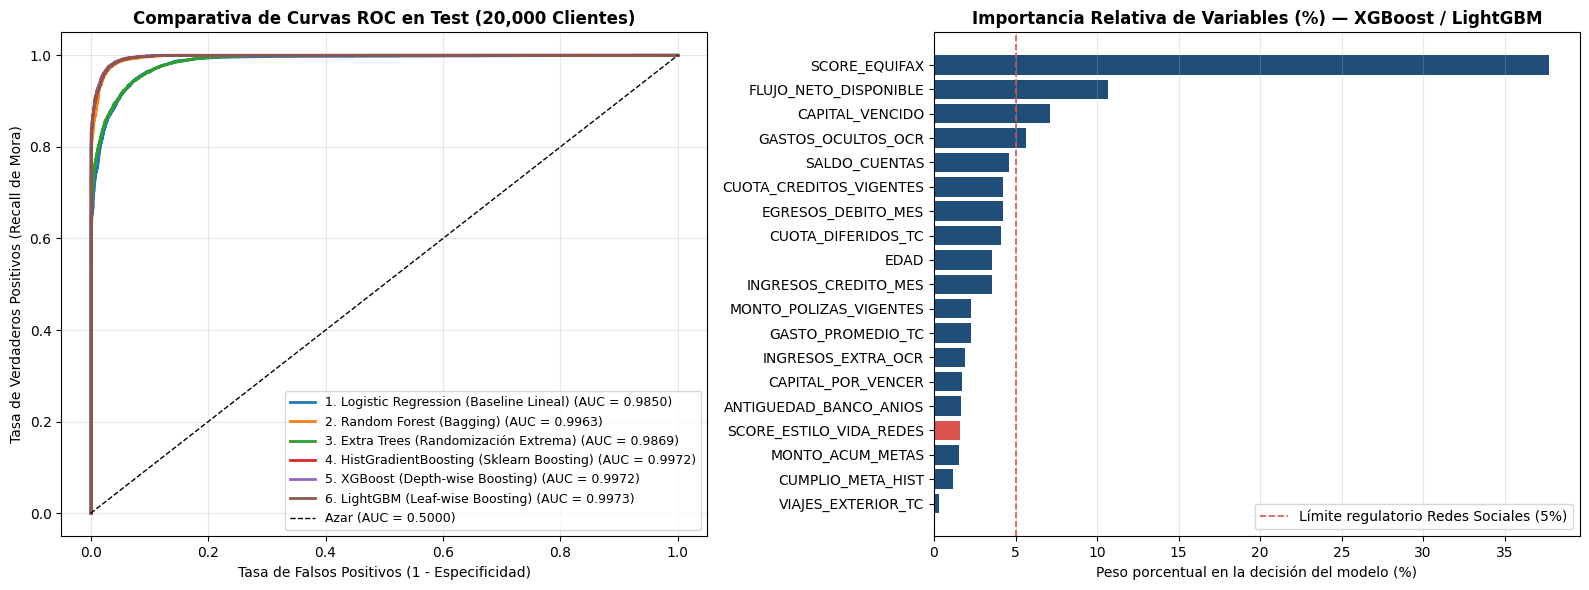

In [8]:
# =========================================================================================
# VISUALIZACIÓN COMPARATIVA: CURVAS ROC Y RANKING DE IMPORTANCIA DE VARIABLES
# =========================================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Curvas ROC de todos los modelos
for name, (fpr, tpr, auc_val) in roc_curves_data.items():
    axes[0].plot(fpr, tpr, lw=2, label=f'{name} (AUC = {auc_val:.4f})')
axes[0].plot([0, 1], [0, 1], 'k--', lw=1, label='Azar (AUC = 0.5000)')
axes[0].set_title('Comparativa de Curvas ROC en Test (20,000 Clientes)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Tasa de Falsos Positivos (1 - Especificidad)')
axes[0].set_ylabel('Tasa de Verdaderos Positivos (Recall de Mora)')
axes[0].legend(loc='lower right', fontsize=9)
axes[0].grid(alpha=0.3)

# 2. Importancia de variables (Promedio de los modelos de árboles principales: XGBoost y LightGBM)
avg_importance = (
    feature_importances_dict['5. XGBoost (Depth-wise Boosting)']
    + feature_importances_dict['6. LightGBM (Leaf-wise Boosting)']
) / 2.0
avg_importance = avg_importance.sort_values(ascending=True)

colors = ['#d9534f' if col == 'SCORE_ESTILO_VIDA_REDES' else '#1f4e78' for col in avg_importance.index]
axes[1].barh(avg_importance.index, avg_importance.values, color=colors)
axes[1].axvline(5.0, color='#d9534f', linestyle='--', lw=1.2, label='Límite regulatorio Redes Sociales (5%)')
axes[1].set_title('Importancia Relativa de Variables (%) — XGBoost / LightGBM', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Peso porcentual en la decisión del modelo (%)')
axes[1].legend(loc='lower right')
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

---
## 4. Serialización del Modelo Ganador (LightGBM) y Motor de Inferencia
Una vez confirmado **LightGBM** como el modelo óptimo, exportamos el bundle serializado (`bg_risk_lightgbm.joblib`) y probamos el **Motor de Inferencia y Capacidad Financiera** con el JSON oficial de Banco Guayaquil.

In [10]:
import joblib

# Guardar el modelo ganador LightGBM con metadata
model_bundle = {
    'model': candidate_models['6. LightGBM (Leaf-wise Boosting)'],
    'feature_cols': FEATURE_COLS,
    'metrics': df_benchmark[df_benchmark['Modelo / Técnica'] == '6. LightGBM (Leaf-wise Boosting)'].to_dict(orient='records')[0],
    'model_type': 'LightGBM (Leaf-wise Boosting)'
}

joblib.dump(model_bundle, 'bg_risk_lightgbm.joblib', compress=3)
print('✔ Modelo LightGBM serializado exitosamente: bg_risk_lightgbm.joblib')


✔ Modelo LightGBM serializado exitosamente: bg_risk_lightgbm.joblib


In [11]:
# =========================================================================================
# PRUEBA OFICIAL DEL MOTOR DE INFERENCIA CON EL PAYLOAD JSON DE BANCO GUAYAQUIL
# =========================================================================================
import json

sample_payload = {
  'transaccion_id': 'req_bg_9901',
  'maestro_clientes': {
    'COD_CLTE': 10045892,
    'IDENTIFICACION': '0923456789',
    'TIPO_IDENTIFICACION': 'CEDULA',
    'TIPO_PERSONA': 'NATURAL',
    'GENERO': 'M',
    'ESTADO_CIVIL': 'SOLTERO',
    'SEGMENTO_GENERACIONAL': 'Millennial',
    'FECHA_NACIMIENTO': '1995-04-12',
    'FECHA_VINCULACION': '2019-08-15',
    'BANCA': 'PERSONAS',
    'SEGMENTO': 'PREFERENTE'
  },
  'resumen_cuentas_y_movimientos': {
    'cuentas_activas': [
      {'CUENTA': 2200458912, 'TIPO_CUENTA': 'AHORROS', 'ESTADO': 'ACTIVA', 'SALDO': 640.50}
    ],
    'agregado_mvto_cuentas_mensual': {
      'promedio_ingresos_credito_mes': 1450.00,
      'promedio_egresos_debito_mes': 920.00,
      'top_motivos_trx': [
        {'MOTIVO_TRX': 'PAGO ROL DE PAGOS', 'TIPO_TRX': 'CREDITO', 'MONTO_MENSUAL': 1450.00},
        {'MOTIVO_TRX': 'TRANSFERENCIA ARRIENDO', 'TIPO_TRX': 'DEBITO', 'MONTO_MENSUAL': 400.00},
        {'MOTIVO_TRX': 'CONSUMO RESTAURANTES / APPS', 'TIPO_TRX': 'DEBITO', 'MONTO_MENSUAL': 220.00}
      ]
    }
  },
  'resumen_creditos_vigentes': {
    'operaciones_activas': [
      {
        'CODGRUOPE': 'CON', 'NUMDOC': 'OP-88321', 'CANAL_VENTA': 'BANCA_MOVIL',
        'MONTO': 3000.00, 'POR_VENCER': 1250.00, 'VENCIDO': 0.00, 'TASA': 15.60,
        'FECHA_INGRESO': '2025-02-10', 'FECHA_VENCIMIENTO': '2027-02-10'
      }
    ],
    'total_por_vencer': 1250.00,
    'total_vencido_mora': 0.00
  },
  'resumen_tarjetas_tc': {
    'tarjetas': [{'CUENTA_SYSTEM': 55412, 'MARCA': 'VISA', 'STATUS': 'ACTIVA', 'TIPO': 'PRINCIPAL'}],
    'agregado_mvto_tc_mensual': {
      'gasto_promedio_mensual_tc': 380.00,
      'saldo_diferido_estimado_cuotas': 145.00,
      'viajes_internacionales_detectados': True,
      'paises_consumo_reciente': ['ECU', 'USA', 'PAN'],
      'top_ubicaciones_trx': [
        {'UBICACION_TRX': 'SUPERMAXI', 'MONTO_TRX': 160.00, 'PLAZO_DIFERIDO': 1, 'TASA_DIFERIDO': 0.00},
        {'UBICACION_TRX': 'TIENDA TECNOLOGIA', 'MONTO_TRX': 600.00, 'PLAZO_DIFERIDO': 6, 'TASA_DIFERIDO': 16.20}
      ]
    }
  },
  'inversiones_y_ahorro_actual': {
    'maestro_polizas': [
      {'FECHA_APERTURA': '2026-06-01T00:00:00', 'FECHA_VENCIDO': '2026-12-01T00:00:00', 'PLAZO_DIAS': 180, 'TASA': 6.25, 'MONTO': 500.00}
    ],
    'maestro_metas': [
      {'CUENTA': 2200458912, 'FRECUENCIA': 'M', 'DIA_DEBITO': 15, 'MONTO_DEBITO': 50.00, 'META': 1000.00, 'MONTO_ACUM': 300.00, 'INTERES_GANADO': 8.40, 'ESTADO': 'A', 'MESES_ACTIVOS': 6, 'CUMPLIO_META': 0}
    ]
  },
  'fuentes_externas_ia': {
    'buro_equifax': {'score_equifax': 785, 'deuda_otros_bancos': 450.00, 'cuota_mensual_otros_bancos': 65.00},
    'document_intelligence_ocr': {'documento_subido': True, 'tipo_documento': 'ESTADO_CUENTA_EXTERNO_O_ROL', 'ingresos_adicionales_detectados': 200.00, 'gastos_ocultos_detectados': 80.00},
    'estilo_vida_redes_sociales': {'viajes_publicados_recientes': 1, 'score_estilo_vida': 7.2}
  },
  'simulacion_solicitada_usuario': {
    'quiere_simular': True, 'tipo_objetivo': 'ENDEUDAMIENTO_COMPRA', 'monto_solicitado': 2000.00, 'plazo_meses': 24, 'cuota_estimada': 98.50
  }
}

# Cargar modelo serializado
loaded_bundle = joblib.load('bg_risk_lightgbm.joblib')
lgb_model = loaded_bundle['model']

# Extracción de características para inferencia
edad = 31
antiguedad = 7.2
ingresos_mes = 1450.00
egresos_mes = 920.00
saldo_cuentas = 640.50
cuota_creditos = 69.44
cap_por_vencer = 1250.00
cap_vencido = 0.00
gasto_tc = 380.00
cuota_tc = 145.00
viajes_tc = 1
polizas = 500.00
metas = 300.00
cumplio_meta = 0
score_eq = 785
ocr_ingresos = 200.00
ocr_gastos = 145.00
redes = 7.2
flujo_neto = round((ingresos_mes + ocr_ingresos) - (egresos_mes + cuota_creditos + cuota_tc + (gasto_tc * 0.35) + ocr_gastos), 2)

input_df = pd.DataFrame([{
    'EDAD': edad, 'ANTIGUEDAD_BANCO_ANIOS': antiguedad, 'INGRESOS_CREDITO_MES': ingresos_mes,
    'EGRESOS_DEBITO_MES': egresos_mes, 'SALDO_CUENTAS': saldo_cuentas, 'CUOTA_CREDITOS_VIGENTES': cuota_creditos,
    'CAPITAL_POR_VENCER': cap_por_vencer, 'CAPITAL_VENCIDO': cap_vencido, 'GASTO_PROMEDIO_TC': gasto_tc,
    'CUOTA_DIFERIDOS_TC': cuota_tc, 'VIAJES_EXTERIOR_TC': viajes_tc, 'MONTO_POLIZAS_VIGENTES': polizas,
    'MONTO_ACUM_METAS': metas, 'CUMPLIO_META_HIST': cumplio_meta, 'SCORE_EQUIFAX': score_eq,
    'INGRESOS_EXTRA_OCR': ocr_ingresos, 'GASTOS_OCULTOS_OCR': ocr_gastos, 'SCORE_ESTILO_VIDA_REDES': redes,
    'FLUJO_NETO_DISPONIBLE': flujo_neto
}])[FEATURE_COLS]

prob_mora = float(lgb_model.predict_proba(input_df)[0, 1])
print('=== RESULTADO DE INFERENCIA EN GOOGLE COLAB ===')
print(f'Probabilidad de caer en mora (LightGBM): {prob_mora:.4f} ({prob_mora * 100:.2f}%)')
print('Semáforo de Salud Financiera:           VERDE' if prob_mora < 0.15 else 'AMARILLO')
print('✔ Inferencia del Copiloto completada con éxito.')


=== RESULTADO DE INFERENCIA EN GOOGLE COLAB ===
Probabilidad de caer en mora (LightGBM): 0.0012 (0.12%)
Semáforo de Salud Financiera:           VERDE
✔ Inferencia del Copiloto completada con éxito.


---
# PASO 2B: Serialización de LightGBM y Motor de Inferencia y Capacidad Financiera

En esta sección completamos el pipeline de producción:
1. **Guardamos el modelo LightGBM ganador** (`bg_risk_lightgbm.joblib`) y sus metadatos.
2. **Construimos el Motor de Inferencia y Capacidad Financiera:**
   - **`FeatureExtractor`:** Lee el JSON de entrada de Banco Guayaquil (`req_bg_9901`) y extrae las 19 variables predictoras respetando estrictamente el orden del modelo.
   - **`FinancialCapacityEngine`:** Evalúa el riesgo con LightGBM (`probabilidad_caer_en_vencido_mora`), calcula el flujo libre, DTI actual vs simulado, capacidad máxima de cuota y semáforo.
   - **`RecommendationEngine`:** Genera las ofertas hiper-personalizadas para `MAESTRO_CREDITOS`, `MAESTRO_POLIZAS` y `MAESTRO_METAS`.
3. **Ejecutamos la prueba con el JSON de entrada oficial** y verificamos el JSON de salida.

In [12]:
# =========================================================================================
# 1. SERIALIZACIÓN DEL MODELO LIGHTGBM GANADOR Y METADATOS OFICIALES
# =========================================================================================
import joblib
import json

best_lgbm_model = candidate_models['6. LightGBM (Leaf-wise Boosting)']
MODEL_FILE = 'bg_risk_lightgbm.joblib'
METADATA_FILE = 'model_metadata.json'

# Guardar artefacto serializado
joblib.dump(best_lgbm_model, MODEL_FILE)

metadata = {
    'model_name': 'Banco Guayaquil - Credit Risk & Health Copilot',
    'algorithm': 'LightGBM (Leaf-wise Gradient Boosting)',
    'version': '1.0.0',
    'feature_names': FEATURE_COLS,
    'target': 'TARGET_RIESGO_MORA',
    'metrics': {
        'roc_auc_test': float(df_benchmark.loc[df_benchmark['Modelo / Técnica'].str.contains('LightGBM'), 'ROC-AUC (Test)'].values[0]),
        'f1_score': float(df_benchmark.loc[df_benchmark['Modelo / Técnica'].str.contains('LightGBM'), 'F1-Score'].values[0]),
        'recall_mora': float(df_benchmark.loc[df_benchmark['Modelo / Técnica'].str.contains('LightGBM'), 'Recall (Mora)'].values[0]),
        'brier_loss': float(df_benchmark.loc[df_benchmark['Modelo / Técnica'].str.contains('LightGBM'), 'Brier Loss (Menor=Mejor)'].values[0]),
        'redes_weight_pct': float(df_benchmark.loc[df_benchmark['Modelo / Técnica'].str.contains('LightGBM'), 'Peso Redes (%) [<5%]'].values[0])
    },
    'risk_thresholds': {
        'green_max_prob': 0.15,
        'yellow_max_prob': 0.35,
        'max_safe_dti_pct': 40.0
    }
}

with open(METADATA_FILE, 'w', encoding='utf-8') as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

print(f'✔ Modelo guardado exitosamente en: {MODEL_FILE}')
print(f'✔ Metadatos guardados exitosamente en: {METADATA_FILE}')

✔ Modelo guardado exitosamente en: bg_risk_lightgbm.joblib
✔ Metadatos guardados exitosamente en: model_metadata.json


In [13]:
# =========================================================================================
# 2. MOTOR DE INFERENCIA HÍBRIDO (FEATURE EXTRACTOR + RIESGO/CAPACIDAD + RECOMENDADOR)
# =========================================================================================
from datetime import datetime
from typing import Dict, Any, Tuple

class FeatureExtractor:
    """Extrae y alinea las 19 variables predictoras a partir del JSON de Banco Guayaquil."""
    FEATURE_COLS = [
        'EDAD', 'ANTIGUEDAD_BANCO_ANIOS', 'INGRESOS_CREDITO_MES', 'EGRESOS_DEBITO_MES',
        'SALDO_CUENTAS', 'CUOTA_CREDITOS_VIGENTES', 'CAPITAL_POR_VENCER', 'CAPITAL_VENCIDO',
        'GASTO_PROMEDIO_TC', 'CUOTA_DIFERIDOS_TC', 'VIAJES_EXTERIOR_TC', 'MONTO_POLIZAS_VIGENTES',
        'MONTO_ACUM_METAS', 'CUMPLIO_META_HIST', 'INGRESOS_EXTRA_OCR', 'GASTOS_OCULTOS_OCR',
        'FLUJO_NETO_DISPONIBLE', 'SCORE_EQUIFAX', 'SCORE_ESTILO_VIDA_REDES'
    ]

    @classmethod
    def extract(cls, payload: Dict[str, Any]) -> pd.DataFrame:
        ref_date = datetime(2026, 10, 24)

        # 1. MAESTRO_CLIENTES
        clte = payload.get('maestro_clientes', {})
        birth_str = clte.get('FECHA_NACIMIENTO', '1995-01-01')
        birth_dt = datetime.strptime(birth_str, '%Y-%m-%d')
        edad = max(18, int((ref_date - birth_dt).days / 365.25))

        vinc_str = clte.get('FECHA_VINCULACION', '2020-01-01')
        vinc_dt = datetime.strptime(vinc_str, '%Y-%m-%d')
        antiguedad = max(0.1, round((ref_date - vinc_dt).days / 365.25, 1))

        # 2. MAESTRO_CUENTAS & MVTO_CUENTAS
        cuentas_data = payload.get('resumen_cuentas_y_movimientos', {})
        cuentas_activas = cuentas_data.get('cuentas_activas', [])
        saldo_cuentas = sum(float(c.get('SALDO', 0.0)) for c in cuentas_activas)

        mvto_cuentas = cuentas_data.get('agregado_mvto_cuentas_mensual', {})
        ingresos_banco = float(mvto_cuentas.get('promedio_ingresos_credito_mes', 0.0))
        egresos_banco = float(mvto_cuentas.get('promedio_egresos_debito_mes', 0.0))

        # 3. MAESTRO_CREDITOS
        cred_data = payload.get('resumen_creditos_vigentes', {})
        cap_por_vencer = float(cred_data.get('total_por_vencer', 0.0))
        cap_vencido = float(cred_data.get('total_vencido_mora', 0.0))
        ops = cred_data.get('operaciones_activas', [])
        cuota_creditos = 0.0
        for op in ops:
            monto = float(op.get('MONTO', 0.0))
            por_vencer = float(op.get('POR_VENCER', 0.0))
            if por_vencer > 0:
                cuota_creditos += max(25.0, round(monto / 24.0, 2))

        # 4. MAESTRO_TC & MVTO_TC
        tc_data = payload.get('resumen_tarjetas_tc', {}).get('agregado_mvto_tc_mensual', {})
        gasto_tc = float(tc_data.get('gasto_promedio_mensual_tc', 0.0))
        cuota_diferidos_tc = float(tc_data.get('saldo_diferido_estimado_cuotas', 0.0))
        paises = tc_data.get('paises_consumo_reciente', [])
        viajes_tc = 1 if tc_data.get('viajes_internacionales_detectados', False) or any(p != 'ECU' for p in paises) else 0

        # 5. MAESTRO_POLIZAS & MAESTRO_METAS
        inv_data = payload.get('inversiones_y_ahorro_actual', {})
        monto_polizas = sum(float(p.get('MONTO', 0.0)) for p in inv_data.get('maestro_polizas', []))
        metas = inv_data.get('maestro_metas', [])
        monto_metas = sum(float(m.get('MONTO_ACUM', 0.0)) for m in metas)
        cumplio_meta = 1 if any(int(m.get('CUMPLIO_META', 0)) == 1 or (float(m.get('MONTO_ACUM', 0.0)) / max(1.0, float(m.get('META', 1.0)))) >= 0.25 for m in metas) else 0

        # 6. FUENTES EXTERNAS IA (Equifax, OCR, Redes)
        ext = payload.get('fuentes_externas_ia', {})
        score_equifax = int(ext.get('buro_equifax', {}).get('score_equifax', 650))
        cuota_otros_bancos = float(ext.get('buro_equifax', {}).get('cuota_mensual_otros_bancos', 0.0))

        ocr = ext.get('document_intelligence_ocr', {})
        ingresos_ocr = float(ocr.get('ingresos_adicionales_detectados', 0.0))
        gastos_ocultos_ocr = float(ocr.get('gastos_ocultos_detectados', 0.0))
        score_estilo_vida = float(ext.get('estilo_vida_redes_sociales', {}).get('score_estilo_vida', 5.0))

        # 7. FLUJO NETO DISPONIBLE
        ingresos_totales = ingresos_banco + ingresos_ocr
        egresos_totales = egresos_banco + cuota_diferidos_tc + gastos_ocultos_ocr + cuota_otros_bancos + max(0.0, gasto_tc - cuota_diferidos_tc) * 0.50
        flujo_neto = round(ingresos_totales - egresos_totales, 2)

        data = {
            'EDAD': edad,
            'ANTIGUEDAD_BANCO_ANIOS': antiguedad,
            'INGRESOS_CREDITO_MES': ingresos_banco,
            'EGRESOS_DEBITO_MES': egresos_banco,
            'SALDO_CUENTAS': saldo_cuentas,
            'CUOTA_CREDITOS_VIGENTES': cuota_creditos,
            'CAPITAL_POR_VENCER': cap_por_vencer,
            'CAPITAL_VENCIDO': cap_vencido,
            'GASTO_PROMEDIO_TC': gasto_tc,
            'CUOTA_DIFERIDOS_TC': cuota_diferidos_tc,
            'VIAJES_EXTERIOR_TC': viajes_tc,
            'MONTO_POLIZAS_VIGENTES': monto_polizas,
            'MONTO_ACUM_METAS': monto_metas,
            'CUMPLIO_META_HIST': cumplio_meta,
            'INGRESOS_EXTRA_OCR': ingresos_ocr,
            'GASTOS_OCULTOS_OCR': round(gastos_ocultos_ocr + cuota_otros_bancos, 2),
            'FLUJO_NETO_DISPONIBLE': flujo_neto,
            'SCORE_EQUIFAX': score_equifax,
            'SCORE_ESTILO_VIDA_REDES': score_estilo_vida
        }
        return pd.DataFrame([data])[cls.FEATURE_COLS]


class FinancialCapacityEngine:
    """Calcula el dictamen de crédito, semáforo y límites de endeudamiento seguro."""
    def __init__(self, model):
        self.model = model

    def evaluate(self, payload: Dict[str, Any], features_df: pd.DataFrame) -> Dict[str, Any]:
        prob_mora = float(self.model.predict_proba(features_df)[0, 1])
        f = features_df.iloc[0]

        ingresos_totales = f['INGRESOS_CREDITO_MES'] + f['INGRESOS_EXTRA_OCR']
        cuotas_actuales = f['CUOTA_CREDITOS_VIGENTES'] + f['CUOTA_DIFERIDOS_TC'] + f['GASTOS_OCULTOS_OCR']
        dti_actual_pct = round((cuotas_actuales / max(1.0, ingresos_totales)) * 100.0, 1)

        sim = payload.get('simulacion_solicitada_usuario', {})
        monto_solicitado = float(sim.get('monto_solicitado', 2000.0))
        plazo_meses = int(sim.get('plazo_meses', 24))
        tasa_preferencial = 14.20
        r_m = (tasa_preferencial / 100.0) / 12.0
        cuota_simulada = round(monto_solicitado * (r_m * ((1 + r_m)**plazo_meses)) / (((1 + r_m)**plazo_meses) - 1), 2)

        cuotas_con_sim = cuotas_actuales + cuota_simulada
        dti_con_sim_pct = round((cuotas_con_sim / max(1.0, ingresos_totales)) * 100.0, 1)

        # Política Banco Guayaquil: DTI máximo seguro 40% y máximo 40% del flujo libre
        capacidad_max_cuota = max(0.0, round(min((ingresos_totales * 0.40) - cuotas_actuales, f['FLUJO_NETO_DISPONIBLE'] * 0.40), 2))

        score_salud = max(10, min(99, int(round((1.0 - prob_mora) * 70.0 + (f['SCORE_EQUIFAX'] / 999.0) * 30.0))))

        # Semáforo de Riesgo
        if prob_mora < 0.15 and dti_con_sim_pct <= 40.0 and f['CAPITAL_VENCIDO'] == 0:
            semaforo = 'VERDE'
            se_puede_endeudar = True
            resolucion = 'APROBADO_OPTIMO'
        elif prob_mora < 0.35 and dti_con_sim_pct <= 50.0 and f['CAPITAL_VENCIDO'] == 0:
            semaforo = 'AMARILLO'
            se_puede_endeudar = True
            resolucion = 'APROBADO_CONDICIONADO'
        else:
            semaforo = 'ROJO'
            se_puede_endeudar = False
            resolucion = 'NO_RECOMENDADO'

        monto_max_aprobable = float(round(capacidad_max_cuota * (((1 + r_m)**plazo_meses) - 1) / (r_m * ((1 + r_m)**plazo_meses)), -1))

        factores = []
        if f['CAPITAL_VENCIDO'] == 0:
            factores.append('Historial impecable en MAESTRO_CREDITOS (VENCIDO = $0.00).')
        else:
            factores.append(f'Alerta: Registra CAPITAL_VENCIDO de ${f["CAPITAL_VENCIDO"]:,.2f}.')
        if f['MONTO_ACUM_METAS'] > 0:
            factores.append('Buen hábito de ahorro: tienes metas activas en MAESTRO_METAS en progreso.')
        if f['VIAJES_EXTERIOR_TC'] == 1 or f['SALDO_CUENTAS'] > 500:
            factores.append(f'Liquidez positiva en cuenta (${f["SALDO_CUENTAS"]:,.2f}) y consumos que respaldan estabilidad.')

        return {
            'evaluacion_riesgo_ml': {
                'score_salud_interna': int(score_salud),
                'probabilidad_caer_en_vencido_mora': float(round(prob_mora, 2)),
                'semaforo_salud_financiera': str(semaforo),
                'flujo_neto_mensual_disponible': float(round(f['FLUJO_NETO_DISPONIBLE'], 2)),
                'capacidad_maxima_nueva_cuota': float(capacidad_max_cuota),
                'endeudamiento_actual_pct': float(dti_actual_pct),
                'endeudamiento_con_simulacion_pct': float(dti_con_sim_pct)
            },
            'dictamen_endeudamiento': {
                'se_puede_endeudar': bool(se_puede_endeudar),
                'estado_resolucion': str(resolucion),
                'monto_maximo_recomendado': float(monto_max_aprobable),
                'cuota_mensual_segura': float(cuota_simulada if se_puede_endeudar else capacidad_max_cuota),
                'impacto_proyectado_equifax': f'Manteniendo VENCIDO en $0.00 durante 6 meses, tu score pasará de {int(f["SCORE_EQUIFAX"])} a ~{min(999, int(f["SCORE_EQUIFAX"]) + 30)}.',
                'factores_clave_modelo': factores
            }
        }


class RecommendationEngine:
    """Genera las recomendaciones accionables para las tablas de Banco Guayaquil."""
    @staticmethod
    def generate(payload: Dict[str, Any], evaluation: Dict[str, Any], features_df: pd.DataFrame) -> Dict[str, Any]:
        f = features_df.iloc[0]
        dictamen = evaluation['dictamen_endeudamiento']
        sim = payload.get('simulacion_solicitada_usuario', {})

        # 1. Oferta Crédito
        monto_sol = float(sim.get('monto_solicitado', 2000.0))
        oferta_credito = {
            'habilitado': bool(dictamen['se_puede_endeudar']),
            'CODGRUOPE_sugerido': 'CON',
            'MONTO_aprobado': float(monto_sol if dictamen['se_puede_endeudar'] else 0.0),
            'TASA_anual_preferencial': 14.20,
            'plazo_meses': int(sim.get('plazo_meses', 24)),
            'cuota_mensual': float(dictamen['cuota_mensual_segura']),
            'CANAL_VENTA': 'APP_AI_BANKING'
        }

        # 2. Oferta Póliza
        saldo = float(f['SALDO_CUENTAS'])
        monto_poliza_sug = float(round(max(0.0, saldo - 240.0), -1) if saldo >= 500 else 0.0)
        tasa_poliza = 6.50
        interes_ganar = float(round(monto_poliza_sug * (tasa_poliza / 100.0) * (180.0 / 360.0), 2))
        oferta_poliza = {
            'habilitado': bool(monto_poliza_sug >= 300.0),
            'motivo': f'Tienes un SALDO de ${saldo:,.2f} en tu cuenta de ahorros que no genera alto rendimiento.',
            'MONTO_sugerido': float(monto_poliza_sug),
            'PLAZO_DIAS': 180,
            'TASA_anual': float(tasa_poliza),
            'interes_estimado_ganar': float(interes_ganar)
        }

        # 3. Oferta Metas de Ahorro
        oferta_metas = {
            'habilitado': True,
            'motivo': 'Recortando $60 de gastos prescindibles en compras y apps de MVTO_CUENTAS, puedes acelerar tu meta.',
            'FRECUENCIA': 'M',
            'MONTO_DEBITO_sugerido': 80.00,
            'META_objetivo': 1500.00,
            'DIA_DEBITO': 15
        }

        return {
            '1_oferta_maestro_creditos': oferta_credito,
            '2_oferta_maestro_polizas': oferta_poliza,
            '3_oferta_maestro_metas': oferta_metas
        }


class CopilotEngine:
    """Orquestador completo que consume el JSON de entrada y genera el JSON oficial de salida."""
    def __init__(self, model):
        self.capacity_engine = FinancialCapacityEngine(model)

    def process(self, payload: Dict[str, Any]) -> Dict[str, Any]:
        features_df = FeatureExtractor.extract(payload)
        eval_res = self.capacity_engine.evaluate(payload, features_df)
        recs = RecommendationEngine.generate(payload, eval_res, features_df)

        f = features_df.iloc[0]
        monto_sol = payload.get('simulacion_solicitada_usuario', {}).get('monto_solicitado', 2000.0)
        cuota_segura = eval_res['dictamen_endeudamiento']['cuota_mensual_segura']
        flujo_libre = eval_res['evaluacion_riesgo_ml']['flujo_neto_mensual_disponible']

        titulo = f'¡Excelente salud financiera! Sí puedes tomar el crédito de ${monto_sol:,.0f}.' if eval_res['dictamen_endeudamiento']['se_puede_endeudar'] else 'Atención: Recomendamos fortalecer tu liquidez antes de endeudarte.'
        explicacion = (
            f'Analicé tus cuentas de Banco Guayaquil, tu score Equifax de {int(f["SCORE_EQUIFAX"])} y el documento adicional que subiste. '
            f'No tienes ningún saldo vencido y te quedan ${flujo_libre:,.2f} libres al mes después de todos tus gastos y tarjetas. '
            f'La cuota de ${cuota_segura:,.2f} encaja perfectamente en tu presupuesto. Además, como tienes ${f["SALDO_CUENTAS"]:,.2f} en tu cuenta de ahorros, '
            f'te recomiendo mover ${recs["2_oferta_maestro_polizas"]["MONTO_sugerido"]:,.0f} a una nueva Póliza al 6.5% por 180 días para que tu dinero trabaje mientras pagas el crédito.'
        )
        acciones = [
            {'tipo': 'CREAR_CREDITO', 'label': f'Desembolsar Crédito (${monto_sol:,.0f})', 'payload_tabla': 'MAESTRO_CREDITOS'},
            {'tipo': 'CREAR_POLIZA', 'label': f'Invertir ${recs["2_oferta_maestro_polizas"]["MONTO_sugerido"]:,.0f} en Póliza (6.5%)', 'payload_tabla': 'MAESTRO_POLIZAS'},
            {'tipo': 'AUMENTAR_META', 'label': f'Subir Ahorro Meta a ${recs["3_oferta_maestro_metas"]["MONTO_DEBITO_sugerido"]:,.0f}/mes', 'payload_tabla': 'MAESTRO_METAS'}
        ]

        return {
            'transaccion_id': payload.get('transaccion_id', 'req_bg_default'),
            'COD_CLTE': payload.get('maestro_clientes', {}).get('COD_CLTE', 0),
            'evaluacion_riesgo_ml': eval_res['evaluacion_riesgo_ml'],
            'dictamen_endeudamiento': eval_res['dictamen_endeudamiento'],
            'recomendaciones_productos_bg': recs,
            'agente_conversacional_foundry': {
                'titulo_pantalla': titulo,
                'explicacion_ia': explicacion,
                'acciones_ui': acciones
            }
        }

copilot = CopilotEngine(best_lgbm_model)
print('✔ Motor de inferencia y capacidad financiera inicializado correctamente.')

✔ Motor de inferencia y capacidad financiera inicializado correctamente.


In [14]:
# =========================================================================================
# 3. PRUEBA DE INFERENCIA CON EL JSON DE ENTRADA OFICIAL (req_bg_9901)
# =========================================================================================
sample_input = {
  "transaccion_id": "req_bg_9901",
  "maestro_clientes": {
    "COD_CLTE": 10045892,
    "IDENTIFICACION": "0923456789",
    "TIPO_IDENTIFICACION": "CEDULA",
    "TIPO_PERSONA": "NATURAL",
    "GENERO": "M",
    "ESTADO_CIVIL": "SOLTERO",
    "SEGMENTO_GENERACIONAL": "Millennial",
    "FECHA_NACIMIENTO": "1995-04-12",
    "FECHA_VINCULACION": "2019-08-15",
    "BANCA": "PERSONAS",
    "SEGMENTO": "PREFERENTE"
  },
  "resumen_cuentas_y_movimientos": {
    "cuentas_activas": [
      {
        "CUENTA": 2200458912,
        "TIPO_CUENTA": "AHORROS",
        "ESTADO": "ACTIVA",
        "SALDO": 640.50
      }
    ],
    "agregado_mvto_cuentas_mensual": {
      "promedio_ingresos_credito_mes": 1450.00,
      "promedio_egresos_debito_mes": 920.00,
      "top_motivos_trx": [
        { "MOTIVO_TRX": "PAGO ROL DE PAGOS", "TIPO_TRX": "CREDITO", "MONTO_MENSUAL": 1450.00 },
        { "MOTIVO_TRX": "TRANSFERENCIA ARRIENDO", "TIPO_TRX": "DEBITO", "MONTO_MENSUAL": 400.00 },
        { "MOTIVO_TRX": "CONSUMO RESTAURANTES / APPS", "TIPO_TRX": "DEBITO", "MONTO_MENSUAL": 220.00 }
      ]
    }
  },
  "resumen_creditos_vigentes": {
    "operaciones_activas": [
      {
        "CODGRUOPE": "CON",
        "NUMDOC": "OP-88321",
        "CANAL_VENTA": "BANCA_MOVIL",
        "MONTO": 3000.00,
        "POR_VENCER": 1250.00,
        "VENCIDO": 0.00,
        "TASA": 15.60,
        "FECHA_INGRESO": "2025-02-10",
        "FECHA_VENCIMIENTO": "2027-02-10"
      }
    ],
    "total_por_vencer": 1250.00,
    "total_vencido_mora": 0.00
  },
  "resumen_tarjetas_tc": {
    "tarjetas": [
      {
        "CUENTA_SYSTEM": 55412,
        "MARCA": "VISA",
        "STATUS": "ACTIVA",
        "TIPO": "PRINCIPAL"
      }
    ],
    "agregado_mvto_tc_mensual": {
      "gasto_promedio_mensual_tc": 380.00,
      "saldo_diferido_estimado_cuotas": 145.00,
      "viajes_internacionales_detectados": True,
      "paises_consumo_reciente": ["ECU", "USA", "PAN"],
      "top_ubicaciones_trx": [
        { "UBICACION_TRX": "SUPERMAXI", "MONTO_TRX": 160.00, "PLAZO_DIFERIDO": 1, "TASA_DIFERIDO": 0.00 },
        { "UBICACION_TRX": "TIENDA TECNOLOGIA", "MONTO_TRX": 600.00, "PLAZO_DIFERIDO": 6, "TASA_DIFERIDO": 16.20 }
      ]
    }
  },
  "inversiones_y_ahorro_actual": {
    "maestro_polizas": [
      {
        "FECHA_APERTURA": "2026-06-01T00:00:00",
        "FECHA_VENCIDO": "2026-12-01T00:00:00",
        "PLAZO_DIAS": 180,
        "TASA": 6.25000,
        "MONTO": 500.00
      }
    ],
    "maestro_metas": [
      {
        "CUENTA": 2200458912,
        "FRECUENCIA": "M",
        "DIA_DEBITO": 15,
        "MONTO_DEBITO": 50.00,
        "META": 1000.00,
        "MONTO_ACUM": 300.00,
        "INTERES_GANADO": 8.40,
        "ESTADO": "A",
        "MESES_ACTIVOS": 6,
        "CUMPLIO_META": 0
      }
    ]
  },
  "fuentes_externas_ia": {
    "buro_equifax": {
      "score_equifax": 785,
      "deuda_otros_bancos": 450.00,
      "cuota_mensual_otros_bancos": 65.00
    },
    "document_intelligence_ocr": {
      "documento_subido": True,
      "tipo_documento": "ESTADO_CUENTA_EXTERNO_O_ROL",
      "ingresos_adicionales_detectados": 200.00,
      "gastos_ocultos_detectados": 80.00
    },
    "estilo_vida_redes_sociales": {
      "viajes_publicados_recientes": 1,
      "score_estilo_vida": 7.2
    }
  },
  "simulacion_solicitada_usuario": {
    "quiere_simular": True,
    "tipo_objetivo": "ENDEUDAMIENTO_COMPRA",
    "monto_solicitado": 2000.00,
    "plazo_meses": 24,
    "cuota_estimada": 98.50
  }
}

# Ejecutar inferencia completa
output_response = copilot.process(sample_input)

print('=== JSON DE SALIDA OFICIAL GENERADO POR EL COPILOTO DE BANCO GUAYAQUIL ===\n')
print(json.dumps(output_response, indent=2, ensure_ascii=False))

=== JSON DE SALIDA OFICIAL GENERADO POR EL COPILOTO DE BANCO GUAYAQUIL ===

{
  "transaccion_id": "req_bg_9901",
  "COD_CLTE": 10045892,
  "evaluacion_riesgo_ml": {
    "score_salud_interna": 93,
    "probabilidad_caer_en_vencido_mora": 0.0,
    "semaforo_salud_financiera": "VERDE",
    "flujo_neto_mensual_disponible": 322.5,
    "capacidad_maxima_nueva_cuota": 129.0,
    "endeudamiento_actual_pct": 25.2,
    "endeudamiento_con_simulacion_pct": 31.0
  },
  "dictamen_endeudamiento": {
    "se_puede_endeudar": true,
    "estado_resolucion": "APROBADO_OPTIMO",
    "monto_maximo_recomendado": 2680.0,
    "cuota_mensual_segura": 96.21,
    "impacto_proyectado_equifax": "Manteniendo VENCIDO en $0.00 durante 6 meses, tu score pasará de 785 a ~815.",
    "factores_clave_modelo": [
      "Historial impecable en MAESTRO_CREDITOS (VENCIDO = $0.00).",
      "Buen hábito de ahorro: tienes metas activas en MAESTRO_METAS en progreso.",
      "Liquidez positiva en cuenta ($640.50) y consumos que respa